# Which GPU work did PyTorch launch?

`capture` profiles one warmed-up training step and returns `prof.events()`.
`rows` holds every event once, with `launcher_id` pointing at the event that
launched it (a CPU op's `cpu_parent`, or a kernel's CUDA launch call), so
`aten::mm -> cudaLaunchKernel -> kernel` is a chain of `launcher_id` links.

Module hooks record `forward::<module_fqn>` scopes, and autograd node hooks restore
the same path as `backward::<module_fqn>` during backward. A kernel belongs to its
nearest module scope; with none it is `<unattributed>`. `aggregate_kernels` does the
attribution and raises if a kernel is owned by a module but never reaches the root scope.

1. Setup and capture
2. Every kernel with its module
3. Time per module
4. Timeline
5. FLOPs check
6. Appendix: what each id is, and one kernel's launch chain

In [24]:
import pandas as pd
import torch
from profile_events import (
    aggregate_kernels,
    display_timeline,
    link_events,
    module_scopes,
    transformer_matmul_comparison,
)

from models.transformer import Transformer

model = Transformer(
    vocab_size=100,
    d_model=32,
    d_ff=128,
    sequence_length=250,
    num_layers=2,
    num_heads=2,
    rope_theta=10000,
    device="cuda",  # has to agree with app.GPU; the preflight checks it
    dtype="torch.float32",  # strings parsed in the worker container
)
tokens = torch.randint(
    0, 100, (8, 250),
    generator=torch.Generator().manual_seed(0),
)

In [25]:
import modal

import main

app = modal.App("profile-events")
# The worker image, so its torch is the uv.lock version that unpickles the events locally.
# The container imports profile_events for module_scopes.
image = main.worker_image.add_local_python_source("profile_events")


@app.function(image=image, gpu="T4", timeout=300)
def capture(declaration, tokens, warmup_steps=5, autocast=False) -> list:
    """Warm up full training steps, then profile one step on the same model.

    Warmup includes forward, loss, backward and optimizer.step so CUDA libraries
    and optimizer state are initialized. Warmup events are not recorded.
    autocast runs forward and loss under fp16 autocast, without loss scaling.
    """
    import torch
    from torch import nn
    from torch.profiler import ProfilerActivity, profile, record_function

    torch.manual_seed(0)
    model = declaration.build()
    tokens = tokens.to("cuda")
    model.train()
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
    # Next-token prediction: each position predicts the following input token.
    targets = tokens[:, 1:].reshape(-1)

    def train_step():
        with record_function("train::zero_grad"):
            optimizer.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16, enabled=autocast):
            with record_function("train::forward"):
                logits = model(tokens)
            with record_function("train::loss"):
                loss = nn.functional.cross_entropy(
                    logits[:, :-1, :].reshape(-1, logits.shape[-1]), targets
                )
        with record_function("train::backward"):
            loss.backward()
        with record_function("train::optimizer_step"):
            optimizer.step()

    # Complete warmup before profiling: no queued warmup work enters the trace.
    for _ in range(warmup_steps):
        train_step()
    torch.cuda.synchronize()

    with profile(
        activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA],
        record_shapes=True,
        with_stack=False,
        with_flops=True,
        profile_memory=True,
    ) as prof, module_scopes(model):
        train_step()
        # Kernels run asynchronously. Wait for them inside the profiler so every launched
        # activity has finished, and been recorded, before collection stops.
        torch.cuda.synchronize()
    # The FunctionEvents themselves: they pickle with their cpu_parent/cpu_children references.
    return list(prof.events())

In [26]:
# enable_output streams image builds and the container's logs into this cell.
with app.run():
    function_events = capture.remote(model, tokens, warmup_steps=5)
print(f"{len(function_events)} events")

4679 events


In [27]:
def to_rows(function_events):
    position = {id(event): i for i, event in enumerate(function_events)}
    raw_rows = (
        pd.DataFrame([vars(event) for event in function_events])
        .rename(columns={"id": "correlation_id"})
        .drop(columns=["cpu_parent", "cpu_children", "kernels"])
        .assign(launcher_id=pd.array(
            [position.get(id(event.cpu_parent)) for event in function_events], dtype="Int64"))
        .rename_axis("index")
    )
    rows = link_events(raw_rows)
    assert rows.index.equals(raw_rows.index)  # every event keeps its row index
    return rows


rows = to_rows(function_events)

## Every kernel and its module

In [28]:
# Raises if a module-owned kernel never reaches the root scope.
groups, kernels, flop_sources = aggregate_kernels(rows, depth=2)
unattributed = kernels["module_fqn"].eq("<unattributed>")
print(f"{len(kernels)} kernels, {unattributed.sum()} unattributed")
assert not unattributed.all(), "No kernel has a module: check module_scopes and root"

# Sort tables by phase in causal order, then module.
phase_order = {p: i for i, p in enumerate(["zero_grad", "forward", "loss", "backward", "optimizer_step", "unscoped"])}
causal = lambda level: level.map(phase_order) if level.name == "phase" else level

362 kernels, 57 unattributed


In [29]:
# Unattributed kernels show module_fqn "<unattributed>".
kernel_table = kernels[["name", "phase", "module_fqn", "owner_fqn", "duration_us", "gpu_start_us"]].sort_values(
    ["phase", "module_fqn", "gpu_start_us"], key=causal)
display(kernel_table)
# display(kernel_table[unattributed].head())

,name,phase,module_fqn,owner_fqn,duration_us,gpu_start_us
index,,,,,,
11,"void at::native::vectorized_gather_kernel<16, ...",forward,model.embedding,model.embedding,11.744,3931.874
1054,volta_sgemm_128x32_tn,forward,model.linear,model.linear,22.208,29154.673
1002,void at::native::vectorized_elementwise_kernel...,forward,model.norm,model.norm,3.840,27829.276
1005,"void at::native::reduce_kernel<512, 1, at::nat...",forward,model.norm,model.norm,13.984,27915.195
1008,void at::native::vectorized_elementwise_kernel...,forward,model.norm,model.norm,3.488,28038.746
...,...,...,...,...,...,...
4557,void at::native::(anonymous namespace)::multi_...,optimizer_step,<unattributed>,NaN,7.904,95899.400
4665,void at::native::(anonymous namespace)::multi_...,optimizer_step,<unattributed>,NaN,7.136,96437.988
4668,void at::native::(anonymous namespace)::multi_...,optimizer_step,<unattributed>,NaN,6.560,96504.643


## Time per module

In [30]:
# gpu_time_us sums kernel durations; gpu_span_us also includes gaps between launches.
display(groups[["kernel_count", "gpu_time_us", "gpu_span_us", "estimated_flops"]].sort_index(key=causal))

kernel_count  gpu_time_us  gpu_span_us  \
phase          module_fqn                                                
forward        model.embedding             1       11.744       11.744   
               model.linear                1       22.208       22.208   
               model.norm                  6       36.864      741.818   
               model.tblocks             110     1300.757    23234.143   
loss           <unattributed>              3       43.904      176.959   
backward       <unattributed>             46      223.678    64070.989   
               model.embedding             7       60.544      387.485   
               model.linear                3       50.176      106.399   
               model.norm                 15      104.512     1525.204   
               model.tblocks             162     2487.016    56216.238   
optimizer_step <unattributed>              8       57.728      943.193   

                                estimated_flops  
phase          module_fqn                        
forward        model.embedding              0.0  
               model.linear          12800000.0  
               model.norm               66000.0  
               model.tblocks        260776000.0  
loss           <unattributed>               0.0  
backward       <unattributed>          256000.0  
               model.embedding           2000.0  
               model.linear          25600000.0  
               model.norm              324000.0  
               model.tblocks        524000000.0  
optimizer_step <unattributed>               0.0

## Timeline

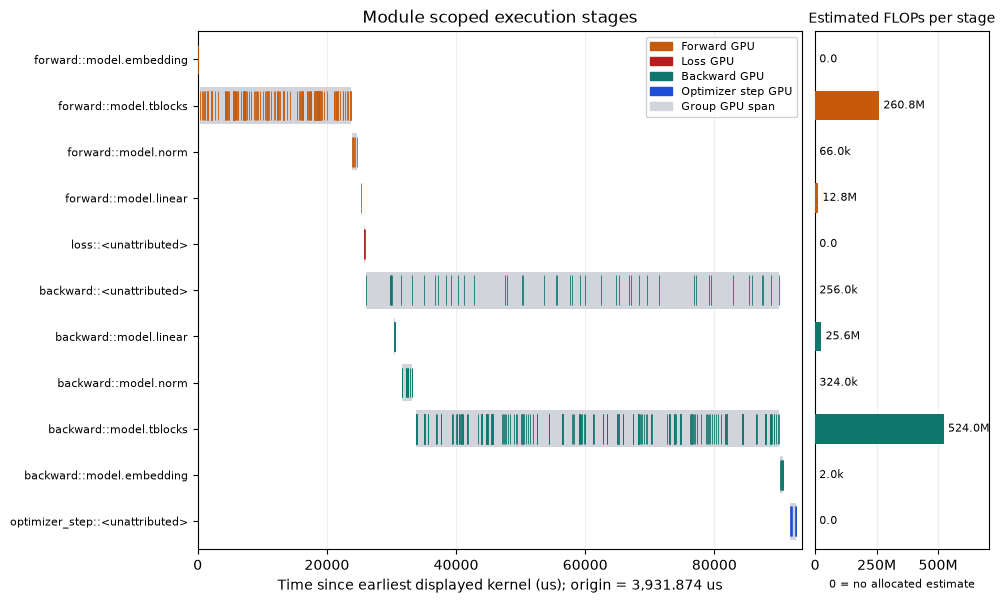

In [31]:
display_timeline(groups, kernels, figsize=(10, 6), show_flops=True)

## FLOPs check

In [32]:
from dataclasses import replace

batch, sequence = tokens.shape
parameter_count = sum(parameter.numel() for parameter in replace(model, device="cpu").build().parameters())
print(f"Parameters: {parameter_count:,}; tokens: {batch * sequence:,}")
print(f"6 × all parameters × tokens: {6 * parameter_count * batch * sequence / 1e6:,.3f} MFLOPs")
print("Comparison below in MFLOPs; matrix estimates exclude normalization, activations, loss and optimizer work.")
phase_comparison, stage_comparison = transformer_matmul_comparison(model, tokens, rows)
display(phase_comparison.div(1e6).round(6))
display(stage_comparison.div(1e6).round(6))
# 0 reported non-matrix FLOPs is not proof of zero work: many operations have
# no estimate. Backward = 2*forward applies to this unfrozen dense model's
# matmuls; freezing weights, detaching tensors or changing the model alters it.

Parameters: 39,328; tokens: 2,000
6 × all parameters × tokens: 471.936 MFLOPs
Comparison below in MFLOPs; matrix estimates exclude normalization, activations, loss and optimizer work.


,analytical_matmul_flops,profiler_matmul_flops,profiler_total_flops,profiler_other_flops,matmul_difference
phase,,,,,
forward,271.872,271.872,273.642,1.770,0.0
backward,543.744,543.744,550.182,6.438,0.0
forward + backward,815.616,815.616,823.824,8.208,0.0


analytical_matmul_flops  \
phase    module_fqn                                           
backward model.linear                                25.600   
         model.tblocks.0.attention                  160.768   
         model.tblocks.0.ffn                         98.304   
         model.tblocks.1.attention                  160.768   
         model.tblocks.1.ffn                         98.304   
forward  model.linear                                12.800   
         model.tblocks.0.attention                   80.384   
         model.tblocks.0.ffn                         49.152   
         model.tblocks.1.attention                   80.384   
         model.tblocks.1.ffn                         49.152   

                                    profiler_matmul_flops  difference  
phase    module_fqn                                                    
backward model.linear                              25.600         0.0  
         model.tblocks.0.attention                160.768         0.0  
         model.tblocks.0.ffn                       98.304         0.0  
         model.tblocks.1.attention                160.768         0.0  
         model.tblocks.1.ffn                       98.304         0.0  
forward  model.linear                              12.800         0.0  
         model.tblocks.0.attention                 80.384         0.0  
         model.tblocks.0.ffn                       49.152         0.0  
         model.tblocks.1.attention                 80.384         0.0  
         model.tblocks.1.ffn                       49.152         0.0

## Autocast check

Same step under fp16 autocast. Casts are expected to appear as extra kernels; module time should shrink where matmuls move to tensor cores.

In [33]:
with modal.enable_output(), app.run():
    autocast_events = capture.remote(model, tokens, warmup_steps=5, autocast=True)
autocast_groups, autocast_kernels, _ = aggregate_kernels(to_rows(autocast_events), depth=4)
comparison = pd.concat(
    {"fp32": groups[["kernel_count", "gpu_time_us"]], "autocast": autocast_groups[["kernel_count", "gpu_time_us"]]},
    axis=1,
).sort_index(key=causal)
comparison["speedup"] = comparison[("fp32", "gpu_time_us")] / comparison[("autocast", "gpu_time_us")]
display(comparison)
print(f"unattributed kernels: fp32 {unattributed.sum()}, autocast {autocast_kernels['module_fqn'].eq('<unattributed>').sum()}")

✓ Initialized. View run at 
https://modal.com/apps/ocanphys/main/ap-PVq2iLkGZ37yk44mOQ478o
⠋ Initializing...
⠸ Creating objects...objects...
├── ⠋ Creating mount PythonPackage:profile_events: Finalizing index of 1 files
⠦ Creating objects...
├── 🔨 Created mount PythonPackage:profile_events
├── 🔨 Created mount PythonPackage:config, PythonPackage:system, 
│   PythonPackage:launcher, PythonPackage:artifacts, PythonPackage:models
⠇ Creating objects...
├── 🔨 Created mount PythonPackage:profile_events
├── 🔨 Created mount PythonPackage:config, PythonPackage:system, 
│   PythonPackage:launcher, PythonPackage:artifacts, PythonPackage:models
└── 🔨 Created function capture.
✓ Created objects.
├── 🔨 Created mount PythonPackage:profile_events
├── 🔨 Created mount PythonPackage:config, PythonPackage:system, 
│   PythonPackage:launcher, PythonPackage:artifacts, PythonPackage:models
└── 🔨 Created function capture.
⠦ Loading images (1 containers initializing)... View app at 
⠏ Loading images (1 containe

fp32              \
                                         kernel_count gpu_time_us   
phase          module_fqn                                           
forward        model.embedding                    1.0      11.744   
               model.linear                       1.0      22.208   
               model.norm                         6.0      36.864   
               model.tblocks                    110.0    1300.757   
               model.tblocks.0                    NaN         NaN   
               model.tblocks.0.attention          NaN         NaN   
               model.tblocks.0.ffn                NaN         NaN   
               model.tblocks.0.norm1              NaN         NaN   
               model.tblocks.0.norm2              NaN         NaN   
               model.tblocks.1                    NaN         NaN   
               model.tblocks.1.attention          NaN         NaN   
               model.tblocks.1.ffn                NaN         NaN   
               model.tblocks.1.norm1              NaN         NaN   
               model.tblocks.1.norm2              NaN         NaN   
loss           <unattributed>                     3.0      43.904   
backward       <unattributed>                    46.0     223.678   
               model.embedding                    7.0      60.544   
               model.linear                       3.0      50.176   
               model.norm                        15.0     104.512   
               model.tblocks                    162.0    2487.016   
               model.tblocks.0                    NaN         NaN   
               model.tblocks.0.attention          NaN         NaN   
               model.tblocks.0.ffn                NaN         NaN   
               model.tblocks.0.norm1              NaN         NaN   
               model.tblocks.0.norm2              NaN         NaN   
               model.tblocks.1                    NaN         NaN   
               model.tblocks.1.attention          NaN         NaN   
               model.tblocks.1.ffn                NaN         NaN   
               model.tblocks.1.norm1              NaN         NaN   
               model.tblocks.1.norm2              NaN         NaN   
optimizer_step <unattributed>                     8.0      57.728   

                                             autocast               speedup  
                                         kernel_count gpu_time_us            
phase          module_fqn                                                    
forward        model.embedding                    1.0      11.776  0.997283  
               model.linear                       2.0      15.200  1.461053  
               model.norm                         8.0      44.766  0.823482  
               model.tblocks                      NaN         NaN       NaN  
               model.tblocks.0                    3.0      24.384       NaN  
               model.tblocks.0.attention         41.0     414.677       NaN  
               model.tblocks.0.ffn                9.0      66.626       NaN  
               model.tblocks.0.norm1              8.0      44.767       NaN  
               model.tblocks.0.norm2              8.0      45.087       NaN  
               model.tblocks.1                    3.0      24.063       NaN  
               model.tblocks.1.attention         41.0     414.616       NaN  
               model.tblocks.1.ffn                9.0      66.239       NaN  
               model.tblocks.1.norm1              8.0      43.616       NaN  
               model.tblocks.1.norm2              8.0      45.727       NaN  
loss           <unattributed>                     4.0      52.895  0.830022  
backward       <unattributed>                    47.0     216.156  1.034799  
               model.embedding                    7.0      61.408  0.985930  
               model.linear                       4.0      39.295  1.276905  
               model.norm                        17.0     118.55

unattributed kernels: fp32 57, autocast 59


## Appendix

## What each id is

`correlation_id` is `FunctionEvent.id`, which `_parse_kineto_results` fills with
`kineto_event.correlation_id()`. What it counts depends on the kind of row:

| Row (`activity_type`) | `correlation_id` | `linked_correlation_id` | `external_id` |
| --- | --- | --- | --- |
| Frontend: op or `record_function` scope (`cpu_op`, `user_annotation`) | PyTorch's own counter | 0 | `correlation_id` |
| Launch call on the CPU (`cuda_runtime`, `cuda_driver`) | CUPTI's counter | the op's `correlation_id` | `linked_correlation_id` |
| GPU work (`kernel`, `gpu_memcpy`, `gpu_memset`) | CUPTI's counter, equal to its launch call's | the op's `correlation_id` | `linked_correlation_id` |
| GPU span of a scope (`gpu_user_annotation`) | its scope's `correlation_id` | 0 | `correlation_id` |
| Profiler overhead (`overhead`) | reuses the `correlation_id` of the op it interrupted | 0 | 0 |

Two counters share the `correlation_id` column, so every lookup by it is restricted to one kind of row:
in one capture `Optimizer.step`'s GPU span and an unrelated launch call were both 1912.
`external_id` holds no value of its own: `KinetoEvent::externalId()` returns
`linked_correlation_id` when there is one, else `correlation_id`.

In [34]:
# One kernel's launch chain, CPU root -> CUDA launch -> kernel.
kernel_id = kernels.index[0]  # Change this to any kernel row ID.
chain, current = [], kernel_id
while pd.notna(current):
    chain.append(current)
    current = rows.loc[current, "launcher_id"]
print("Module:", kernels.loc[kernel_id, "module_fqn"])
display(rows.loc[chain[::-1]])

Module: model.embedding


,correlation_id,node_id,name,overload_name,trace_name,time_range,thread,fwd_thread,count,input_shapes,...,external_id,linked_correlation_id,event_metadata,structured_input_shapes,structured_input_strides,input_dtypes,python_id,python_parent_id,python_module_id,launcher_id
index,,,,,,,,,,,,,,,,,,,,,
2,3,-1,train::forward,,train::forward,<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,3,0,None,[],[],[],-1,-1,-1,<NA>
3,4,-1,forward::model,,forward::model,<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,4,0,None,[],[],[],-1,-1,-1,2
4,5,-1,forward::model.embedding,,forward::model.embedding,<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,5,0,None,[],[],[],-1,-1,-1,3
5,6,-1,aten::index,,aten::index,<torch.autograd.profiler_util.Interval object ...,1,0,1,"[[100, 32], []]",...,6,0,None,"[[100, 32], []]","[[32, 1], []]","[float, ]",-1,-1,-1,4
10,11,-1,cudaLaunchKernel,,cudaLaunchKernel,<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,6,6,None,[],[],[],-1,-1,-1,5
11,11,-1,"void at::native::vectorized_gather_kernel<16, ...",,"void at::native::vectorized_gather_kernel<16, ...",<torch.autograd.profiler_util.Interval object ...,1,0,1,[],...,6,6,None,[],[],[],-1,-1,-1,10
